In [1]:
#import dependencies: https://github.com/tensorflow/datasets/blob/master/tensorflow_datasets/datasets/stanford_dogs/stanford_dogs_dataset_builder.py
import collections
import os
import re
import xml.etree.ElementTree as ET
import tensorflow as tf
from tensorflow import keras
import tensorflow_datasets.public_api as tfds 
from tensorflow.keras.preprocessing.image import ImageDataGenerator

#to check 
print ("done importing")

done importing


In [2]:
os.getcwd()

'/Users/selinacheah/tensorflow-capstone'

In [3]:
#load dataset
#dataset is downloaded from http://vision.stanford.edu/aditya86/ImageNetDogs/main.html
#make sure dataset is in the same directory!
import tarfile 
file_list = os.listdir('.')
file_list

['annotation.tar',
 '.DS_Store',
 'inceptionV3_model_featureExtraction.h5',
 'file_list.mat',
 'lists.tar',
 'Images',
 'test_data.mat',
 'history_featureExtraction.npy',
 'images.tar',
 'Annotation',
 'train_data.mat',
 'env',
 'test_list.mat',
 'train_list.mat',
 '.ipynb_checkpoints',
 '23-24_CE301_cheah_chi_y',
 'Test.ipynb',
 'WoofAmI.ipynb']

In [4]:
#extract tar files 
for fname in file_list:
    if fname.endswith(".tar"):
        tar = tarfile.open(fname, "r:")
        tar.extractall()
        tar.close
        

In [5]:
#to check .tar files are extracted
os.listdir(".")

['annotation.tar',
 '.DS_Store',
 'inceptionV3_model_featureExtraction.h5',
 'file_list.mat',
 'lists.tar',
 'Images',
 'test_data.mat',
 'history_featureExtraction.npy',
 'images.tar',
 'Annotation',
 'train_data.mat',
 'env',
 'test_list.mat',
 'train_list.mat',
 '.ipynb_checkpoints',
 '23-24_CE301_cheah_chi_y',
 'Test.ipynb',
 'WoofAmI.ipynb']

In [6]:
#import dependencies for training
import numpy as np
from matplotlib import pyplot as plt
from tensorflow.keras import layers
from tensorflow.keras.models import Sequential 
import pathlib 

print("imported")

imported


In [7]:
dataset_dir = 'Images'
os.listdir(dataset_dir)

['n02097658-silky_terrier',
 'n02092002-Scottish_deerhound',
 'n02099849-Chesapeake_Bay_retriever',
 'n02091244-Ibizan_hound',
 'n02095314-wire-haired_fox_terrier',
 'n02091831-Saluki',
 'n02102318-cocker_spaniel',
 'n02104365-schipperke',
 'n02090622-borzoi',
 'n02113023-Pembroke',
 'n02105505-komondor',
 'n02093256-Staffordshire_bullterrier',
 'n02113799-standard_poodle',
 'n02109961-Eskimo_dog',
 'n02089973-English_foxhound',
 'n02099601-golden_retriever',
 'n02095889-Sealyham_terrier',
 'n02085782-Japanese_spaniel',
 'n02097047-miniature_schnauzer',
 'n02110063-malamute',
 'n02105162-malinois',
 'n02086079-Pekinese',
 'n02097130-giant_schnauzer',
 'n02113978-Mexican_hairless',
 'n02107142-Doberman',
 'n02097209-standard_schnauzer',
 'n02115913-dhole',
 'n02106662-German_shepherd',
 'n02106382-Bouvier_des_Flandres',
 'n02110185-Siberian_husky',
 'n02094258-Norwich_terrier',
 'n02093991-Irish_terrier',
 'n02094114-Norfolk_terrier',
 'n02109525-Saint_Bernard',
 'n02093754-Border_terri

In [8]:
#building data pipeline : https://www.youtube.com/watch?v=jztwpsIzEGc
data = tf.keras.utils.image_dataset_from_directory('Images')

Found 20580 files belonging to 120 classes.


2023-11-19 04:59:08.414861: I metal_plugin/src/device/metal_device.cc:1154] Metal device set to: Apple M1
2023-11-19 04:59:08.414886: I metal_plugin/src/device/metal_device.cc:296] systemMemory: 16.00 GB
2023-11-19 04:59:08.414894: I metal_plugin/src/device/metal_device.cc:313] maxCacheSize: 5.33 GB
2023-11-19 04:59:08.415085: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:303] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
2023-11-19 04:59:08.415106: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:269] Created TensorFlow device (/job:localhost/replica:0/task:0/device:GPU:0 with 0 MB memory) -> physical PluggableDevice (device: 0, name: METAL, pci bus id: <undefined>)


In [9]:
#access data pipeline
data_iterator = data.as_numpy_iterator()
data_iterator

In [10]:
#added
train_gen = ImageDataGenerator(validation_split=0.2, 
                               rescale=1.0/255.0,
                                width_shift_range=0.2, # 0.1
                                height_shift_range=0.2, # 0.1
                                horizontal_flip=True)

train_set = train_gen.flow_from_directory(
                               directory=dataset_dir,
                               seed=10,
                               class_mode='sparse',
                               batch_size=32,
                               shuffle=True,
                               target_size=(224, 224),
                               subset='training')



Found 16508 images belonging to 120 classes.


In [11]:
#added
val_gen = ImageDataGenerator(validation_split=0.2, 
                                rescale=1.0/255.0,
                                width_shift_range=0.2, 
                                height_shift_range=0.2,
                                horizontal_flip=True)

val_set = val_gen.flow_from_directory(
                               directory=dataset_dir,
                               seed=10,
                               class_mode='sparse',
                               batch_size=32,
                               shuffle=True,
                               target_size=(224, 224),
                               subset='validation')



Found 4072 images belonging to 120 classes.


In [12]:
#added
class_names = {y: x for x, y in val_set.class_indices.items()}
class_names

{0: 'n02085620-Chihuahua',
 1: 'n02085782-Japanese_spaniel',
 2: 'n02085936-Maltese_dog',
 3: 'n02086079-Pekinese',
 4: 'n02086240-Shih-Tzu',
 5: 'n02086646-Blenheim_spaniel',
 6: 'n02086910-papillon',
 7: 'n02087046-toy_terrier',
 8: 'n02087394-Rhodesian_ridgeback',
 9: 'n02088094-Afghan_hound',
 10: 'n02088238-basset',
 11: 'n02088364-beagle',
 12: 'n02088466-bloodhound',
 13: 'n02088632-bluetick',
 14: 'n02089078-black-and-tan_coonhound',
 15: 'n02089867-Walker_hound',
 16: 'n02089973-English_foxhound',
 17: 'n02090379-redbone',
 18: 'n02090622-borzoi',
 19: 'n02090721-Irish_wolfhound',
 20: 'n02091032-Italian_greyhound',
 21: 'n02091134-whippet',
 22: 'n02091244-Ibizan_hound',
 23: 'n02091467-Norwegian_elkhound',
 24: 'n02091635-otterhound',
 25: 'n02091831-Saluki',
 26: 'n02092002-Scottish_deerhound',
 27: 'n02092339-Weimaraner',
 28: 'n02093256-Staffordshire_bullterrier',
 29: 'n02093428-American_Staffordshire_terrier',
 30: 'n02093647-Bedlington_terrier',
 31: 'n02093754-Border_

In [13]:
#added
num_classification_categories = len(class_names)
print('Number of classes=%d' % num_classification_categories)

Number of classes=120


In [14]:
batch = data_iterator.next() #retrieve a batch of data from iterator 
batch

(array([[[[7.16288757e+00, 1.71681824e+01, 3.94583130e+00],
          [2.63372803e+00, 2.15453186e+01, 5.61080933e+00],
          [1.23481750e+00, 3.03029633e+01, 8.81663513e+00],
          ...,
          [4.65900574e+01, 1.01781677e+02, 7.24837189e+01],
          [4.98379059e+01, 1.07539597e+02, 7.49020996e+01],
          [4.23936615e+01, 1.03648697e+02, 6.81216125e+01]],
 
         [[1.28199310e+01, 2.80306091e+01, 1.28062592e+01],
          [1.52108765e+00, 2.40203247e+01, 5.79844666e+00],
          [3.14759216e+01, 6.49935150e+01, 4.35768433e+01],
          ...,
          [3.92923584e+01, 9.40163116e+01, 4.70299835e+01],
          [3.45034332e+01, 9.42421112e+01, 4.42600708e+01],
          [4.49390717e+01, 1.08903915e+02, 5.56826935e+01]],
 
         [[1.12542725e+00, 2.21581726e+01, 5.01213074e+00],
          [2.31781006e-01, 2.60859222e+01, 6.00584412e+00],
          [1.80153656e+01, 5.04397125e+01, 2.88567963e+01],
          ...,
          [5.56536407e+01, 1.06660385e+02, 6.1564

In [15]:
len(batch)
#calculates no. of elements in the 'batch'. Batch is composed of 2 parts, images and labels

2

In [16]:
#images represented as numpy array
batch[0].shape #image
#shape of an image is represented as (height, width, channels), dimensions and the number of color channels (e.g., 3 for RGB)

(32, 256, 256, 3)

In [17]:
batch[1] #labels

array([ 57,  30,  47,  88,  57, 100,  50,  40,  88,  53,  15,  98,  38,
       108,  82, 103,  85,   7, 113,  73,  61,  43,  98, 115,   4, 102,
        82,  26,  40,  57,  15, 111], dtype=int32)

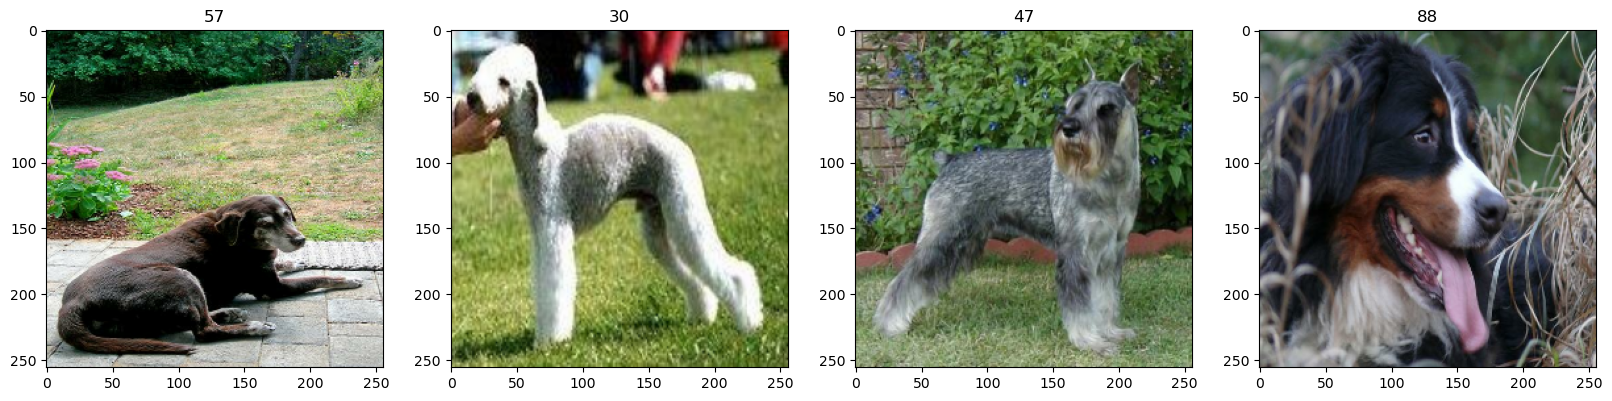

In [18]:
fig, ax = plt.subplots(ncols=4, figsize=(20,20))
for idx, img in enumerate(batch[0][:4]):
    ax[idx].imshow(img.astype(int))
    ax[idx].title.set_text(batch[1][idx]) 

In [19]:
# making values smaller for optimization, range 0-1 (255 is max of rgb)
scaled = batch[0]/255 

In [20]:
scaled.max()

1.0

In [21]:
#preprocessing data - transform raw data into a format suitable for analysis  
#scale data : https://www.tensorflow.org/api_docs/python/tf/data/Dataset#map
data = data.map(lambda x,y: (x/255, y))

In [22]:
scaled_iterator = data.as_numpy_iterator()

In [23]:
batch = scaled_iterator.next()

In [24]:
batch[0].max()

1.0

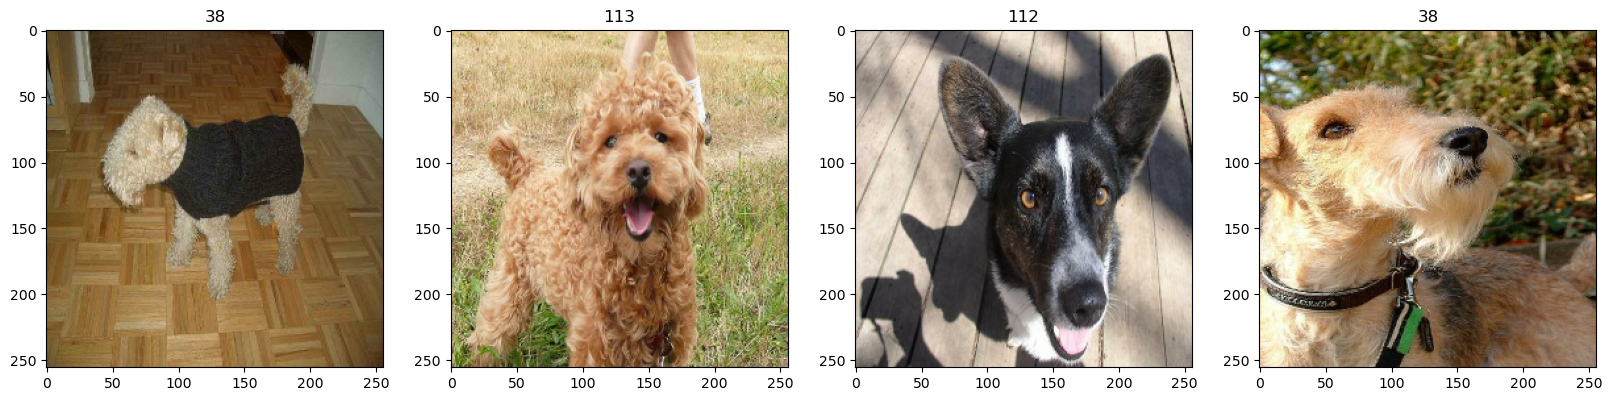

In [25]:
fig, ax = plt.subplots(ncols=4, figsize=(20,20))
for idx, img in enumerate(batch[0][:4]):
    ax[idx].imshow(img)
    ax[idx].title.set_text(batch[1][idx]) 

In [26]:
#split data 
len(data)

644

In [27]:
644*32

20608

In [28]:
train_size = int(len(data)*.7) #higher percentage for training 
val_size = int(len(data)*.2)+1 #evaluate
test_size = int(len(data)*.1)+1 #post training evaluation

print("train size =" , train_size)
print("validation size =" , val_size)
print("test size =" , test_size)

total_size = train_size + val_size + test_size
print ("total size = ", total_size)

train size = 450
validation size = 129
test size = 65
total size =  644


In [29]:
train = data.take(train_size)
val = data.skip(train_size).take(val_size)
test = data.skip(train_size+val_size).take(test_size)

In [30]:
len(test)

65

In [31]:
#import libraries and pre-trained model 
from tensorflow.keras.models import Sequential
from keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout, InputLayer
from keras import layers, models
from keras.models import Sequential
from keras import optimizers
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
from tensorflow.keras.layers import Conv2D, MaxPooling2D,GlobalAveragePooling2D, Input
from tensorflow.keras.layers import Dense, Dropout, Flatten
from tensorflow.keras.models import Sequential, Model
from sklearn import metrics
from tqdm import tqdm


In [32]:
from keras.applications.inception_v3 import InceptionV3

In [33]:
#initialise the base model 
base_model = InceptionV3(#input_shape=(224,224,3),
                          include_top = True,
                          weights = 'imagenet')

base_model.summary()

Model: "inception_v3"
__________________________________________________________________________________________________
 Layer (type)                Output Shape                 Param #   Connected to                  
 input_1 (InputLayer)        [(None, 299, 299, 3)]        0         []                            
                                                                                                  
 conv2d (Conv2D)             (None, 149, 149, 32)         864       ['input_1[0][0]']             
                                                                                                  
 batch_normalization (Batch  (None, 149, 149, 32)         96        ['conv2d[0][0]']              
 Normalization)                                                                                   
                                                                                                  
 activation (Activation)     (None, 149, 149, 32)         0         ['batch_normalizati

 conv2d_11 (Conv2D)          (None, 35, 35, 32)           6144      ['average_pooling2d[0][0]']   
                                                                                                  
 batch_normalization_5 (Bat  (None, 35, 35, 64)           192       ['conv2d_5[0][0]']            
 chNormalization)                                                                                 
                                                                                                  
 batch_normalization_7 (Bat  (None, 35, 35, 64)           192       ['conv2d_7[0][0]']            
 chNormalization)                                                                                 
                                                                                                  
 batch_normalization_10 (Ba  (None, 35, 35, 96)           288       ['conv2d_10[0][0]']           
 tchNormalization)                                                                                
          

                                                                                                  
 activation_17 (Activation)  (None, 35, 35, 96)           0         ['batch_normalization_17[0][0]
                                                                    ']                            
                                                                                                  
 activation_18 (Activation)  (None, 35, 35, 64)           0         ['batch_normalization_18[0][0]
                                                                    ']                            
                                                                                                  
 mixed1 (Concatenate)        (None, 35, 35, 288)          0         ['activation_12[0][0]',       
                                                                     'activation_14[0][0]',       
                                                                     'activation_17[0][0]',       
          

                                                                                                  
 conv2d_28 (Conv2D)          (None, 35, 35, 96)           55296     ['activation_27[0][0]']       
                                                                                                  
 batch_normalization_28 (Ba  (None, 35, 35, 96)           288       ['conv2d_28[0][0]']           
 tchNormalization)                                                                                
                                                                                                  
 activation_28 (Activation)  (None, 35, 35, 96)           0         ['batch_normalization_28[0][0]
                                                                    ']                            
                                                                                                  
 conv2d_26 (Conv2D)          (None, 17, 17, 384)          995328    ['mixed2[0][0]']              
          

 conv2d_30 (Conv2D)          (None, 17, 17, 192)          147456    ['mixed3[0][0]']              
                                                                                                  
 conv2d_33 (Conv2D)          (None, 17, 17, 192)          172032    ['activation_32[0][0]']       
                                                                                                  
 conv2d_38 (Conv2D)          (None, 17, 17, 192)          172032    ['activation_37[0][0]']       
                                                                                                  
 conv2d_39 (Conv2D)          (None, 17, 17, 192)          147456    ['average_pooling2d_3[0][0]'] 
                                                                                                  
 batch_normalization_30 (Ba  (None, 17, 17, 192)          576       ['conv2d_30[0][0]']           
 tchNormalization)                                                                                
          

                                                                    ']                            
                                                                                                  
 average_pooling2d_4 (Avera  (None, 17, 17, 768)          0         ['mixed4[0][0]']              
 gePooling2D)                                                                                     
                                                                                                  
 conv2d_40 (Conv2D)          (None, 17, 17, 192)          147456    ['mixed4[0][0]']              
                                                                                                  
 conv2d_43 (Conv2D)          (None, 17, 17, 192)          215040    ['activation_42[0][0]']       
                                                                                                  
 conv2d_48 (Conv2D)          (None, 17, 17, 192)          215040    ['activation_47[0][0]']       
          

                                                                                                  
 activation_52 (Activation)  (None, 17, 17, 160)          0         ['batch_normalization_52[0][0]
                                                                    ']                            
                                                                                                  
 activation_57 (Activation)  (None, 17, 17, 160)          0         ['batch_normalization_57[0][0]
                                                                    ']                            
                                                                                                  
 average_pooling2d_5 (Avera  (None, 17, 17, 768)          0         ['mixed5[0][0]']              
 gePooling2D)                                                                                     
                                                                                                  
 conv2d_50

 batch_normalization_62 (Ba  (None, 17, 17, 192)          576       ['conv2d_62[0][0]']           
 tchNormalization)                                                                                
                                                                                                  
 batch_normalization_67 (Ba  (None, 17, 17, 192)          576       ['conv2d_67[0][0]']           
 tchNormalization)                                                                                
                                                                                                  
 activation_62 (Activation)  (None, 17, 17, 192)          0         ['batch_normalization_62[0][0]
                                                                    ']                            
                                                                                                  
 activation_67 (Activation)  (None, 17, 17, 192)          0         ['batch_normalization_67[0][0]
          

                                                                                                  
 conv2d_71 (Conv2D)          (None, 8, 8, 320)            552960    ['activation_70[0][0]']       
                                                                                                  
 conv2d_75 (Conv2D)          (None, 8, 8, 192)            331776    ['activation_74[0][0]']       
                                                                                                  
 batch_normalization_71 (Ba  (None, 8, 8, 320)            960       ['conv2d_71[0][0]']           
 tchNormalization)                                                                                
                                                                                                  
 batch_normalization_75 (Ba  (None, 8, 8, 192)            576       ['conv2d_75[0][0]']           
 tchNormalization)                                                                                
          

                                                                                                  
 activation_82 (Activation)  (None, 8, 8, 384)            0         ['batch_normalization_82[0][0]
                                                                    ']                            
                                                                                                  
 activation_83 (Activation)  (None, 8, 8, 384)            0         ['batch_normalization_83[0][0]
                                                                    ']                            
                                                                                                  
 batch_normalization_84 (Ba  (None, 8, 8, 192)            576       ['conv2d_84[0][0]']           
 tchNormalization)                                                                                
                                                                                                  
 activatio

                                                                                                  
 activation_88 (Activation)  (None, 8, 8, 384)            0         ['batch_normalization_88[0][0]
                                                                    ']                            
                                                                                                  
 activation_91 (Activation)  (None, 8, 8, 384)            0         ['batch_normalization_91[0][0]
                                                                    ']                            
                                                                                                  
 activation_92 (Activation)  (None, 8, 8, 384)            0         ['batch_normalization_92[0][0]
                                                                    ']                            
                                                                                                  
 batch_nor

In [34]:
#freezing all weights 
#for layer in base_model.layers:
        #layer.trainable = False
# Unfreeze all layers initially
for layer in base_model.layers:
    layer.trainable = True

# Freeze all layers except the last two
for layer in base_model.layers[:-2]:
    layer.trainable = False

In [35]:
#adding fully connected layers onto model 
x = Flatten()(base_model.output) 


In [36]:
#prevent overfitting by adding dropout layer
#x = layers.Dense(1024, activation='relu', name='fc1')(x)
#x = layers.Dropout(0.5)(x)  # Adding dropout for regularization
#x = layers.Dense(128, activation='relu', name='fc2')(x)

In [37]:
#reduce no. of neurons 
#x = layers.Dense(512, activation='relu', name='fc3')(x)  # Reducing the number of neurons
#x = layers.Dropout(0.5)(x)
#x = layers.Dense(128, activation='relu', name='fc4')(x)

In [38]:
#final layer (output)
prediction = layers.Dense(num_classification_categories, activation='softmax')(x)

In [39]:
#visualise
model = models.Model(inputs=base_model.input, outputs=prediction)
model.summary()

Model: "model"
__________________________________________________________________________________________________
 Layer (type)                Output Shape                 Param #   Connected to                  
 input_1 (InputLayer)        [(None, 299, 299, 3)]        0         []                            
                                                                                                  
 conv2d (Conv2D)             (None, 149, 149, 32)         864       ['input_1[0][0]']             
                                                                                                  
 batch_normalization (Batch  (None, 149, 149, 32)         96        ['conv2d[0][0]']              
 Normalization)                                                                                   
                                                                                                  
 activation (Activation)     (None, 149, 149, 32)         0         ['batch_normalization[0][0

 conv2d_11 (Conv2D)          (None, 35, 35, 32)           6144      ['average_pooling2d[0][0]']   
                                                                                                  
 batch_normalization_5 (Bat  (None, 35, 35, 64)           192       ['conv2d_5[0][0]']            
 chNormalization)                                                                                 
                                                                                                  
 batch_normalization_7 (Bat  (None, 35, 35, 64)           192       ['conv2d_7[0][0]']            
 chNormalization)                                                                                 
                                                                                                  
 batch_normalization_10 (Ba  (None, 35, 35, 96)           288       ['conv2d_10[0][0]']           
 tchNormalization)                                                                                
          

                                                                                                  
 activation_17 (Activation)  (None, 35, 35, 96)           0         ['batch_normalization_17[0][0]
                                                                    ']                            
                                                                                                  
 activation_18 (Activation)  (None, 35, 35, 64)           0         ['batch_normalization_18[0][0]
                                                                    ']                            
                                                                                                  
 mixed1 (Concatenate)        (None, 35, 35, 288)          0         ['activation_12[0][0]',       
                                                                     'activation_14[0][0]',       
                                                                     'activation_17[0][0]',       
          

                                                                                                  
 conv2d_28 (Conv2D)          (None, 35, 35, 96)           55296     ['activation_27[0][0]']       
                                                                                                  
 batch_normalization_28 (Ba  (None, 35, 35, 96)           288       ['conv2d_28[0][0]']           
 tchNormalization)                                                                                
                                                                                                  
 activation_28 (Activation)  (None, 35, 35, 96)           0         ['batch_normalization_28[0][0]
                                                                    ']                            
                                                                                                  
 conv2d_26 (Conv2D)          (None, 17, 17, 384)          995328    ['mixed2[0][0]']              
          

 conv2d_30 (Conv2D)          (None, 17, 17, 192)          147456    ['mixed3[0][0]']              
                                                                                                  
 conv2d_33 (Conv2D)          (None, 17, 17, 192)          172032    ['activation_32[0][0]']       
                                                                                                  
 conv2d_38 (Conv2D)          (None, 17, 17, 192)          172032    ['activation_37[0][0]']       
                                                                                                  
 conv2d_39 (Conv2D)          (None, 17, 17, 192)          147456    ['average_pooling2d_3[0][0]'] 
                                                                                                  
 batch_normalization_30 (Ba  (None, 17, 17, 192)          576       ['conv2d_30[0][0]']           
 tchNormalization)                                                                                
          

                                                                    ']                            
                                                                                                  
 average_pooling2d_4 (Avera  (None, 17, 17, 768)          0         ['mixed4[0][0]']              
 gePooling2D)                                                                                     
                                                                                                  
 conv2d_40 (Conv2D)          (None, 17, 17, 192)          147456    ['mixed4[0][0]']              
                                                                                                  
 conv2d_43 (Conv2D)          (None, 17, 17, 192)          215040    ['activation_42[0][0]']       
                                                                                                  
 conv2d_48 (Conv2D)          (None, 17, 17, 192)          215040    ['activation_47[0][0]']       
          

                                                                                                  
 activation_52 (Activation)  (None, 17, 17, 160)          0         ['batch_normalization_52[0][0]
                                                                    ']                            
                                                                                                  
 activation_57 (Activation)  (None, 17, 17, 160)          0         ['batch_normalization_57[0][0]
                                                                    ']                            
                                                                                                  
 average_pooling2d_5 (Avera  (None, 17, 17, 768)          0         ['mixed5[0][0]']              
 gePooling2D)                                                                                     
                                                                                                  
 conv2d_50

 batch_normalization_62 (Ba  (None, 17, 17, 192)          576       ['conv2d_62[0][0]']           
 tchNormalization)                                                                                
                                                                                                  
 batch_normalization_67 (Ba  (None, 17, 17, 192)          576       ['conv2d_67[0][0]']           
 tchNormalization)                                                                                
                                                                                                  
 activation_62 (Activation)  (None, 17, 17, 192)          0         ['batch_normalization_62[0][0]
                                                                    ']                            
                                                                                                  
 activation_67 (Activation)  (None, 17, 17, 192)          0         ['batch_normalization_67[0][0]
          

                                                                                                  
 conv2d_71 (Conv2D)          (None, 8, 8, 320)            552960    ['activation_70[0][0]']       
                                                                                                  
 conv2d_75 (Conv2D)          (None, 8, 8, 192)            331776    ['activation_74[0][0]']       
                                                                                                  
 batch_normalization_71 (Ba  (None, 8, 8, 320)            960       ['conv2d_71[0][0]']           
 tchNormalization)                                                                                
                                                                                                  
 batch_normalization_75 (Ba  (None, 8, 8, 192)            576       ['conv2d_75[0][0]']           
 tchNormalization)                                                                                
          

                                                                                                  
 activation_82 (Activation)  (None, 8, 8, 384)            0         ['batch_normalization_82[0][0]
                                                                    ']                            
                                                                                                  
 activation_83 (Activation)  (None, 8, 8, 384)            0         ['batch_normalization_83[0][0]
                                                                    ']                            
                                                                                                  
 batch_normalization_84 (Ba  (None, 8, 8, 192)            576       ['conv2d_84[0][0]']           
 tchNormalization)                                                                                
                                                                                                  
 activatio

                                                                                                  
 activation_88 (Activation)  (None, 8, 8, 384)            0         ['batch_normalization_88[0][0]
                                                                    ']                            
                                                                                                  
 activation_91 (Activation)  (None, 8, 8, 384)            0         ['batch_normalization_91[0][0]
                                                                    ']                            
                                                                                                  
 activation_92 (Activation)  (None, 8, 8, 384)            0         ['batch_normalization_92[0][0]
                                                                    ']                            
                                                                                                  
 batch_nor

In [40]:
#compile 
from tensorflow.keras.optimizers import Adam 
model.compile(loss=keras.losses.SparseCategoricalCrossentropy(), 
                 optimizer=keras.optimizers.legacy.Adam(), #'tf.keras.optimizers.Adam` runs slowly on M1
                 metrics=['accuracy'])

my_callbacks = [ModelCheckpoint(filepath='inceptionV3_model_featureExtraction.h5', save_best_only=True)]


In [41]:
#fitting
history = model.fit(
    train_set,
    epochs=1,
    validation_data=val_set,
    callbacks=my_callbacks
)
np.save('history_featureExtraction.npy', [history.history['accuracy'], history.history['val_accuracy']])


2023-11-19 04:59:15.918543: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:114] Plugin optimizer for device_type GPU is enabled.


516/516 [==============================] - ETA: 0s - loss: 4.5689 - accuracy: 0.3135

2023-11-19 05:02:22.857111: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:114] Plugin optimizer for device_type GPU is enabled.
/Users/selinacheah/tensorflow-capstone/env/lib/python3.8/site-packages/keras/src/engine/training.py:3000: UserWarning: You are saving your model as an HDF5 file via `model.save()`. This file format is considered legacy. We recommend using instead the native Keras format, e.g. `model.save('my_model.keras')`.
  saving_api.save_model(


516/516 [==============================] - 231s 444ms/step - loss: 4.5689 - accuracy: 0.3135 - val_loss: 4.3597 - val_accuracy: 0.3664


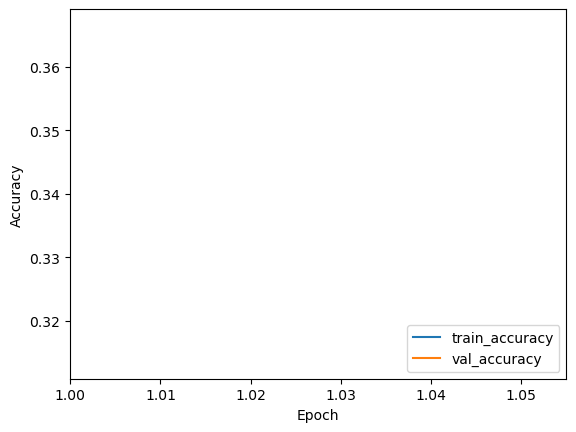

In [42]:
#graph
epochs = range(1, len(history.history['accuracy']) + 1)
plt.plot(epochs, history.history['accuracy'], label='train_accuracy')
plt.plot(epochs, history.history['val_accuracy'], label = 'val_accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.xlim([1, None])
plt.legend(loc='lower right')

In [43]:
#fine-tuning
input_shape = (224, 224, 3)

#specify shape of inputs 
input = layers.Input(shape=input_shape)

#load InceptionV3 again 
base_model = InceptionV3 (weights='imagenet', include_top=False, input_tensor=input)
print (base_model.summary)

<bound method Model.summary of <keras.src.engine.functional.Functional object at 0x3742e8df0>>


In [44]:
#get last layter to add our classifier on top 
last_layer = base_model.output 
#flatten
x = layers.Flatten()(last_layer)


In [45]:
#classifer 
x = layers.Dense(128, activation='relu')(x)
x = layers.Dropout(0.5)(x)
prediction = layers.Dense(num_classification_categories, activation = 'softmax')(x)

In [46]:
#create final model
model = models.Model(inputs=base_model.input, outputs=prediction)
print (model.summary())

Model: "model_1"
__________________________________________________________________________________________________
 Layer (type)                Output Shape                 Param #   Connected to                  
 input_2 (InputLayer)        [(None, 224, 224, 3)]        0         []                            
                                                                                                  
 conv2d_94 (Conv2D)          (None, 111, 111, 32)         864       ['input_2[0][0]']             
                                                                                                  
 batch_normalization_94 (Ba  (None, 111, 111, 32)         96        ['conv2d_94[0][0]']           
 tchNormalization)                                                                                
                                                                                                  
 activation_94 (Activation)  (None, 111, 111, 32)         0         ['batch_normalization_94

                                                                                                  
 conv2d_105 (Conv2D)         (None, 25, 25, 32)           6144      ['average_pooling2d_9[0][0]'] 
                                                                                                  
 batch_normalization_99 (Ba  (None, 25, 25, 64)           192       ['conv2d_99[0][0]']           
 tchNormalization)                                                                                
                                                                                                  
 batch_normalization_101 (B  (None, 25, 25, 64)           192       ['conv2d_101[0][0]']          
 atchNormalization)                                                                               
                                                                                                  
 batch_normalization_104 (B  (None, 25, 25, 96)           288       ['conv2d_104[0][0]']          
 atchNorma

 )                                                                  ]']                           
                                                                                                  
 activation_111 (Activation  (None, 25, 25, 96)           0         ['batch_normalization_111[0][0
 )                                                                  ]']                           
                                                                                                  
 activation_112 (Activation  (None, 25, 25, 64)           0         ['batch_normalization_112[0][0
 )                                                                  ]']                           
                                                                                                  
 mixed1 (Concatenate)        (None, 25, 25, 288)          0         ['activation_106[0][0]',      
                                                                     'activation_108[0][0]',      
          

 )                                                                  ]']                           
                                                                                                  
 conv2d_122 (Conv2D)         (None, 25, 25, 96)           55296     ['activation_121[0][0]']      
                                                                                                  
 batch_normalization_122 (B  (None, 25, 25, 96)           288       ['conv2d_122[0][0]']          
 atchNormalization)                                                                               
                                                                                                  
 activation_122 (Activation  (None, 25, 25, 96)           0         ['batch_normalization_122[0][0
 )                                                                  ]']                           
                                                                                                  
 conv2d_12

                                                                                                  
 conv2d_124 (Conv2D)         (None, 12, 12, 192)          147456    ['mixed3[0][0]']              
                                                                                                  
 conv2d_127 (Conv2D)         (None, 12, 12, 192)          172032    ['activation_126[0][0]']      
                                                                                                  
 conv2d_132 (Conv2D)         (None, 12, 12, 192)          172032    ['activation_131[0][0]']      
                                                                                                  
 conv2d_133 (Conv2D)         (None, 12, 12, 192)          147456    ['average_pooling2d_12[0][0]']
                                                                                                  
 batch_normalization_124 (B  (None, 12, 12, 192)          576       ['conv2d_124[0][0]']          
 atchNorma

 activation_141 (Activation  (None, 12, 12, 160)          0         ['batch_normalization_141[0][0
 )                                                                  ]']                           
                                                                                                  
 average_pooling2d_13 (Aver  (None, 12, 12, 768)          0         ['mixed4[0][0]']              
 agePooling2D)                                                                                    
                                                                                                  
 conv2d_134 (Conv2D)         (None, 12, 12, 192)          147456    ['mixed4[0][0]']              
                                                                                                  
 conv2d_137 (Conv2D)         (None, 12, 12, 192)          215040    ['activation_136[0][0]']      
                                                                                                  
 conv2d_14

 atchNormalization)                                                                               
                                                                                                  
 activation_146 (Activation  (None, 12, 12, 160)          0         ['batch_normalization_146[0][0
 )                                                                  ]']                           
                                                                                                  
 activation_151 (Activation  (None, 12, 12, 160)          0         ['batch_normalization_151[0][0
 )                                                                  ]']                           
                                                                                                  
 average_pooling2d_14 (Aver  (None, 12, 12, 768)          0         ['mixed5[0][0]']              
 agePooling2D)                                                                                    
          

                                                                                                  
 batch_normalization_156 (B  (None, 12, 12, 192)          576       ['conv2d_156[0][0]']          
 atchNormalization)                                                                               
                                                                                                  
 batch_normalization_161 (B  (None, 12, 12, 192)          576       ['conv2d_161[0][0]']          
 atchNormalization)                                                                               
                                                                                                  
 activation_156 (Activation  (None, 12, 12, 192)          0         ['batch_normalization_156[0][0
 )                                                                  ]']                           
                                                                                                  
 activatio

 )                                                                  ]']                           
                                                                                                  
 conv2d_165 (Conv2D)         (None, 5, 5, 320)            552960    ['activation_164[0][0]']      
                                                                                                  
 conv2d_169 (Conv2D)         (None, 5, 5, 192)            331776    ['activation_168[0][0]']      
                                                                                                  
 batch_normalization_165 (B  (None, 5, 5, 320)            960       ['conv2d_165[0][0]']          
 atchNormalization)                                                                               
                                                                                                  
 batch_normalization_169 (B  (None, 5, 5, 192)            576       ['conv2d_169[0][0]']          
 atchNorma

 )                                                                  ]']                           
                                                                                                  
 activation_176 (Activation  (None, 5, 5, 384)            0         ['batch_normalization_176[0][0
 )                                                                  ]']                           
                                                                                                  
 activation_177 (Activation  (None, 5, 5, 384)            0         ['batch_normalization_177[0][0
 )                                                                  ]']                           
                                                                                                  
 batch_normalization_178 (B  (None, 5, 5, 192)            576       ['conv2d_178[0][0]']          
 atchNormalization)                                                                               
          

 )                                                                  ]']                           
                                                                                                  
 activation_182 (Activation  (None, 5, 5, 384)            0         ['batch_normalization_182[0][0
 )                                                                  ]']                           
                                                                                                  
 activation_185 (Activation  (None, 5, 5, 384)            0         ['batch_normalization_185[0][0
 )                                                                  ]']                           
                                                                                                  
 activation_186 (Activation  (None, 5, 5, 384)            0         ['batch_normalization_186[0][0
 )                                                                  ]']                           
          

In [47]:
#freeze all layers except classifier
Layers_to_freeze = len(base_model.layers) #top layers
for layer in model.layers[:Layers_to_freeze]:
    layer.trainable = False
for layer in model.layers[Layers_to_freeze:]:
    layer.trainable = True
    
for i, layer in enumerate(model.layers):
    print(layer.name, layer.trainable)

input_2 False
conv2d_94 False
batch_normalization_94 False
activation_94 False
conv2d_95 False
batch_normalization_95 False
activation_95 False
conv2d_96 False
batch_normalization_96 False
activation_96 False
max_pooling2d_4 False
conv2d_97 False
batch_normalization_97 False
activation_97 False
conv2d_98 False
batch_normalization_98 False
activation_98 False
max_pooling2d_5 False
conv2d_102 False
batch_normalization_102 False
activation_102 False
conv2d_100 False
conv2d_103 False
batch_normalization_100 False
batch_normalization_103 False
activation_100 False
activation_103 False
average_pooling2d_9 False
conv2d_99 False
conv2d_101 False
conv2d_104 False
conv2d_105 False
batch_normalization_99 False
batch_normalization_101 False
batch_normalization_104 False
batch_normalization_105 False
activation_99 False
activation_101 False
activation_104 False
activation_105 False
mixed0 False
conv2d_109 False
batch_normalization_109 False
activation_109 False
conv2d_107 False
conv2d_110 False
bat

In [49]:
#train model
model.compile(loss=keras.losses.SparseCategoricalCrossentropy(),
             optimizer=keras.optimizers.legacy.Adam(),
             metrics=['accuracy'])

my_callbacks = [ModelCheckpoint(filepath='inceptionV3_model_fineTuning.h5', save_best_only=True)]

In [50]:
history = model.fit(
    train_set,
    epochs=1,
    validation_data=val_set,
    callbacks=my_callbacks
)

np.save('history_featureExtraction.npy', [history.history['accuracy'], history.history['val_accuracy']])

2023-11-19 05:18:14.254157: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:114] Plugin optimizer for device_type GPU is enabled.


516/516 [==============================] - ETA: 0s - loss: 71.1951 - accuracy: 0.1987

2023-11-19 05:21:33.700517: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:114] Plugin optimizer for device_type GPU is enabled.


516/516 [==============================] - 245s 470ms/step - loss: 71.1951 - accuracy: 0.1987 - val_loss: 16.6874 - val_accuracy: 0.5182


In [51]:
# freeze bottom layers to train top layers
Layers_to_freeze = len(base_model.layers) 
for layer in model.layers[:Layers_to_freeze]:
    layer.trainable = True
for layer in model.layers[Layers_to_freeze:]:
    layer.trainable = False
    
for i, layer in enumerate(model.layers):
    print(layer.name, layer.trainable)

input_2 True
conv2d_94 True
batch_normalization_94 True
activation_94 True
conv2d_95 True
batch_normalization_95 True
activation_95 True
conv2d_96 True
batch_normalization_96 True
activation_96 True
max_pooling2d_4 True
conv2d_97 True
batch_normalization_97 True
activation_97 True
conv2d_98 True
batch_normalization_98 True
activation_98 True
max_pooling2d_5 True
conv2d_102 True
batch_normalization_102 True
activation_102 True
conv2d_100 True
conv2d_103 True
batch_normalization_100 True
batch_normalization_103 True
activation_100 True
activation_103 True
average_pooling2d_9 True
conv2d_99 True
conv2d_101 True
conv2d_104 True
conv2d_105 True
batch_normalization_99 True
batch_normalization_101 True
batch_normalization_104 True
batch_normalization_105 True
activation_99 True
activation_101 True
activation_104 True
activation_105 True
mixed0 True
conv2d_109 True
batch_normalization_109 True
activation_109 True
conv2d_107 True
conv2d_110 True
batch_normalization_107 True
batch_normalization_

In [52]:
#retrain model
model.compile(loss=keras.losses.SparseCategoricalCrossentropy(),
             optimizer=keras.optimizers.legacy.SGD(learning_rate=0.0001, momentum=0.9),
             metrics=['accuracy'])

my_callbacks = [ModelCheckpoint(filepath='inceptionV3_model_fineTuning.h5', save_best_only=True)]

In [53]:
history = model.fit(
    train_set,
    epochs=1,
    validation_data=val_set,
    callbacks=my_callbacks
)

np.save('history_featureExtraction_2.npy', [history.history['accuracy'], history.history['val_accuracy']])

2023-11-19 05:34:29.396576: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:114] Plugin optimizer for device_type GPU is enabled.


516/516 [==============================] - ETA: 0s - loss: 24.3666 - accuracy: 0.2775

2023-11-19 05:43:19.380639: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:114] Plugin optimizer for device_type GPU is enabled.


516/516 [==============================] - 578s 1s/step - loss: 24.3666 - accuracy: 0.2775 - val_loss: 9.8748 - val_accuracy: 0.4330


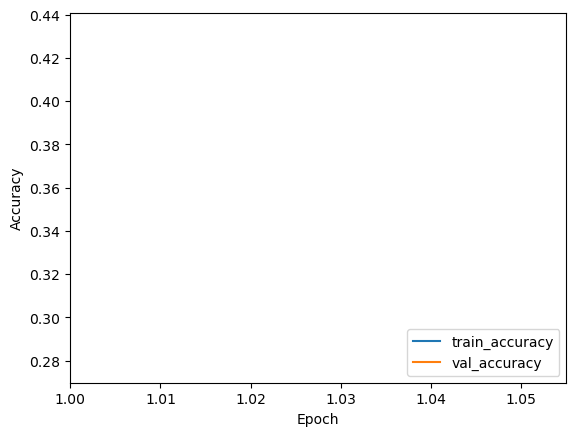

In [54]:
#training graphs
epochs = range(1, len(history.history['accuracy']) + 1)
plt.plot(epochs, history.history['accuracy'], label='train_accuracy')
plt.plot(epochs, history.history['val_accuracy'], label = 'val_accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.xlim([1, None])
plt.legend(loc='lower right')